# EDA 1 — Payment Reliability & Experiment Impact

**Technical review only.** This notebook is the single EDA 1 analytical deliverable. It extends the approved EDA 0 and Sprint 1 without changing their outputs. All documentation is in English.

**Question:** Is Test associated with delayed *observed capture*, does the early D1 difference withstand predefined sensitivities, and what payment-friction evidence is available? Captured timestamps do not prove full settlement. Comparisons conditional on completed projects or observed payment methods are not unqualified policy effects.

**Scope:** D0–D30 capture curve; restricted mean *uncaptured* hours at **D7, D14, D30** (all three use host-cluster bootstrap); D1 robustness; payment method and mixed-method journeys. The registered host is the resampling cluster; the completed project is the time-to-event unit. All timestamps are UTC.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if not (root/'pyproject.toml').exists():
    root = next(p for p in root.parents if (p/'pyproject.toml').exists())
sys.path.insert(0, str(root))
from src.foundation_a import load_raw
from src.foundation_ce import parse_utc
from src.experiment_impact import build_project_panel, SEED
from src.eda1_reliability import (prepare_time_panel, empirical_capture_curve, rmst_horizon,
    metric_project_horizon, build_discordance_flags, friction_tables,
    card_alternative_journeys, label_incident_overlap)
from tests.check_eda1_source_reconciliations import run_audit
frames, provenance = load_raw(root)
hosts, logs = frames['exposures'], frames['payments']
project_all = build_project_panel(hosts, frames['assignments'], logs)
q = prepare_time_panel(project_all)
assert len(hosts)==14708 and len(project_all)==279847 and len(logs)==306957
assert len(q)==201302 and q.assignment_id.is_unique
assert q.covered_D7.all() and q.covered_D14.all()
assert int(q.covered_D30.sum())==200050 and int((~q.covered_D30).sum())==1252
assert q.experiment_group.value_counts().to_dict()=={'test':102447,'control':98855}
display(pd.DataFrame({'validation':['hosts','experiment projects','logs in full extract','D30 conservative projects','D30 last-day uncertain'], 'count':[len(hosts),len(q),len(logs),int(q.covered_D30.sum()),int((~q.covered_D30).sum())]}))

                  validation   count
0                      hosts   14708
1        experiment projects  201302
2       logs in full extract  306957
3  D30 conservative projects  200050
4     D30 last-day uncertain    1252


## A. Continuous first observed capture — D0 to D30

The earliest non-null `captured_at` is the first *recorded* capture timestamp. Events before or exactly at completion are represented at t=0 for the **post-completion** clock; the signed negative durations and flags remain available. Missing captures contribute no observed event. The common D30 cohort requires `completed_at + 30 elapsed days < 2025-12-19 00:00 UTC` because the final-day extraction hour is unknown. This is conservative under the continuous-follow-up premise, **not independent proof of event completeness**. No Kaplan–Meier model is imposed without an observed censoring timestamp.

Pre-completion captures (diagnostic, treated as t=0): 101
D30 conservative denominator: 200050 of 201302


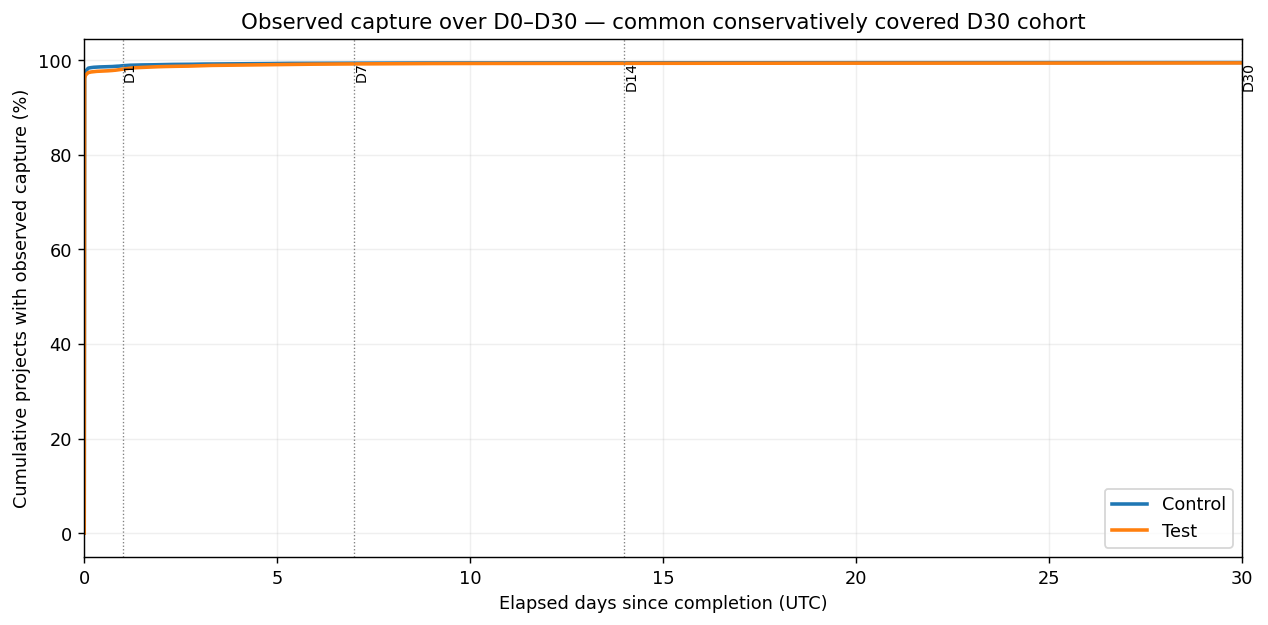

In [2]:
hours = np.unique(np.r_[np.linspace(0,24,97),np.linspace(24,720,290),[0,24,168,336,720]])
curve = empirical_capture_curve(q, hours)
observed = q[['assignment_id','experiment_group','host_id','event_hours','signed_capture_hours','first_capture']].copy()
assert observed.assignment_id.is_unique
assert q.pre_completion.sum() == (q.signed_capture_hours<0).sum()
fig,ax=plt.subplots(figsize=(10,5))
for group in ('control','test'):
    c=curve.loc[curve.group.eq(group)]
    ax.plot(c.days,c.captured_fraction*100,label=group.title(),linewidth=2)
for day in (1,7,14,30):
    ax.axvline(day,color='gray',ls=':',lw=.75)
    ax.text(day,99.8,'D'+str(day),rotation=90,va='top',fontsize=8)
ax.set(xlim=(0,30),xlabel='Elapsed days since completion (UTC)',ylabel='Cumulative projects with observed capture (%)',
       title='Observed capture over D0–D30 — common conservatively covered D30 cohort')
ax.legend(); ax.grid(alpha=.2); plt.tight_layout();plt.show()
print('Pre-completion captures (diagnostic, treated as t=0):',int(q.pre_completion.sum()))
print('D30 conservative denominator:',int(q.covered_D30.sum()),'of',len(q))

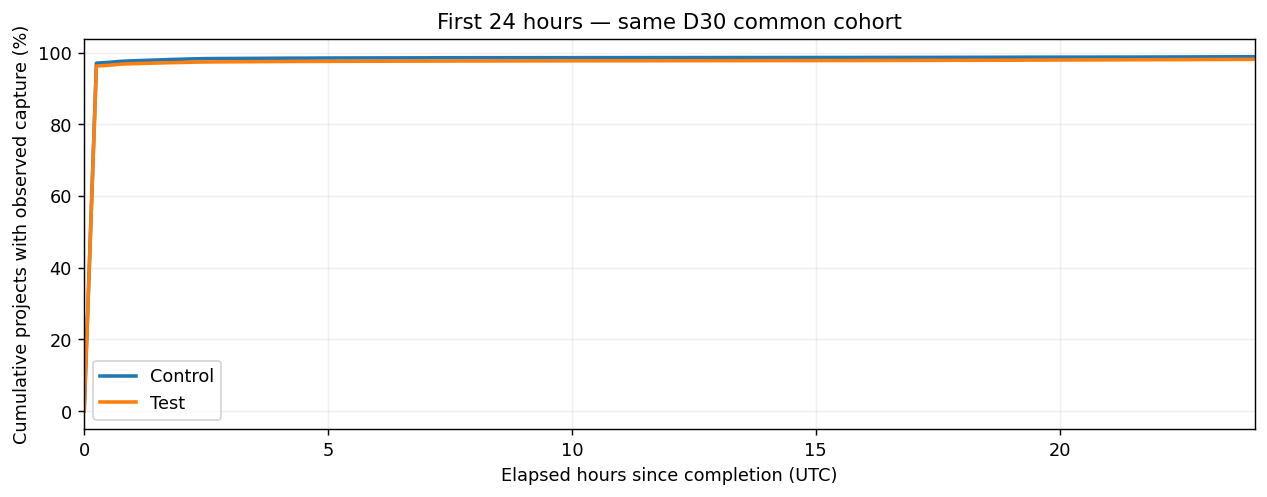

,horizon,group,denominator,captured,capture_rate_pct
0,D1,control,98855,97702,98.833645
1,D1,test,102447,100504,98.103410
2,D7,control,98855,98245,99.382935
3,D7,test,102447,101648,99.220085
4,D14,control,98855,98317,99.455769
5,D14,test,102447,101790,99.358693
6,D30,control,98239,97751,99.503252
7,D30,test,101811,101227,99.426388


In [3]:
fig,ax=plt.subplots(figsize=(10,4))
for group in ('control','test'):
    c=curve.loc[curve.group.eq(group)&curve.hours.le(24)]
    ax.plot(c.hours,c.captured_fraction*100,label=group.title(),linewidth=2)
ax.set(xlim=(0,24),xlabel='Elapsed hours since completion (UTC)', ylabel='Cumulative projects with observed capture (%)',
       title='First 24 hours — same D30 common cohort')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()
# All-complete D1/D7/D14 discrete rates must agree with prior Sprint 1.
rows=[]
for d in (1,7,14,30):
    for group in ('control','test'):
        z=q.loc[q[f'covered_D{d}']&q.experiment_group.eq(group)]
        rows.append({'horizon':f'D{d}','group':group,'denominator':len(z),'captured':int(z[f'event_D{d}'].sum()),
                     'capture_rate_pct':100*z[f'event_D{d}'].mean()})
rates=pd.DataFrame(rows)
assert rates.set_index(['horizon','group']).loc[('D1','control'),'captured']==97702
assert rates.set_index(['horizon','group']).loc[('D1','test'),'captured']==100504
assert rates.set_index(['horizon','group']).loc[('D14','control'),'captured']==98317
assert rates.set_index(['horizon','group']).loc[('D14','test'),'captured']==101790
# Match the curve at all marked times on its explicitly different D30 cohort.
for d in (1,7,14,30):
    for group in ('control','test'):
        z=q.loc[q.covered_D30 & q.experiment_group.eq(group)]
        expected=float(z[f'event_D{d}'].mean())
        got=float(curve.loc[curve.group.eq(group)&curve.hours.eq(24*d),'captured_fraction'].iloc[0])
        assert abs(got-expected)<1e-12
display(rates)

## B. Restricted mean hours without observed capture — D7 / D14 / D30

For a completed project, `min(max(first_capture-completion, 0), horizon)` hours are contributed; no timestamp contributes the full horizon. Estimates are **project-weighted within each group**. The 2,000 stratified bootstrap replicates sample *hosts*, carrying all their projects together, and jointly resample project-level numerator and denominator. This is not the mean only among captured projects. The D30 primary denominator excludes 1,252 final-day-uncertain projects, and D7/D14 are repeated on the **same D30 cohort** to isolate population-composition effects. No unverifiable censoring time is fabricated.

In [4]:
rmst_rows=[]
for d,common in ((7,False),(14,False),(30,False),(7,True),(14,True)):
    rmst_rows.append(rmst_horizon(q,hosts,d,common_D30=common,n_boot=2000,seed=SEED))
rmst=pd.DataFrame(rmst_rows)
assert set(rmst.measure)=={'RMST D7','RMST D14','RMST D30','RMST D7 (D30 cohort)','RMST D14 (D30 cohort)'}
assert (rmst.n_control+rmst.n_test).tolist()==[201302,201302,200050,200050,200050]
display(rmst[['measure','control','test','difference','ci_low','ci_high','n_control','n_test']].round(4))

,measure,control,test,difference,ci_low,ci_high,n_control,n_test
0,RMST D7,1.4888,2.1372,0.6484,0.1228,1.1399,98855,102447
1,RMST D14,2.4519,3.2931,0.8412,-0.0754,1.6616,98855,102447
2,RMST D30,4.4357,5.6570,1.2213,-0.3870,2.7037,98239,101811
3,RMST D7 (D30 cohort),1.4877,2.1401,0.6524,0.1229,1.1467,98239,101811
4,RMST D14 (D30 cohort),2.4517,3.2999,0.8482,-0.0707,1.6688,98239,101811


### D30 final-day cutoff sensitivity (diagnostic, not validated coverage)

As a deliberate **unverified assumption** only, treat the 1,252 projects with D30 deadlines falling on the documented final calendar day as if they had complete D30 observation. Compare the resulting D30 RMST with the conservative full-coverage cohort. Because the extraction closing **hour** is unknown, this diagnostic cannot establish that these five missing-D30 timestamps reflect a fully observed 30-day absence. This is not censor-time estimation or a valid Kaplan–Meier fit.

In [5]:
from src.eda1_reliability import aggregate_cluster_project_means, cluster_ratio_ci
scenario=cluster_ratio_ci(aggregate_cluster_project_means(
    q, hosts, 'restricted_uncaptured_hours_D30'), n_boot=2000, seed=SEED)
scenario['measure']='RMST D30 (last day assumed complete; unverified)'
uncertain_counts=q.loc[~q.covered_D30].groupby('experiment_group').agg(
    projects=('assignment_id','size'), capture_timestamp_by_D30=('event_D30','sum'))
assert int(uncertain_counts.projects.sum())==1252
assert scenario['n_control']+scenario['n_test']==201302
display(pd.DataFrame([scenario])[['measure','control','test','difference','ci_low','ci_high','n_control','n_test']].round(4))
display(uncertain_counts)
# Algebraic check: restricted mean = exact integral of 1-F(t) over [0,H].
for d in (7,14,30):
    for g in ('control','test'):
        z=q.loc[q.experiment_group.eq(g) & q[f'covered_D{d}']]
        H=24*d
        integral=H - np.maximum(H-z.event_hours.dropna().to_numpy(),0).sum()/len(z)
        point=float(rmst.loc[rmst.measure.eq(f'RMST D{d}'),g].iloc[0])
        assert abs(integral-point)<1e-10
print('Curve integral = RMST, exact algebraic verification: PASS')

Curve integral = RMST, exact algebraic verification: PASS


,measure,control,test,difference,ci_low,ci_high,n_control,n_test
0,RMST D30 (last day assumed complete; unverified),4.4352,5.6431,1.2079,-0.3961,2.6754,98855,102447


,projects,capture_timestamp_by_D30
experiment_group,,
control,616,613
test,636,634


## C. D1 robustness and observed financial-status disagreements

Four scenarios are prespecified. Removing incident completions or discordant projects changes the analysis population and **does not** create an incident-free counterfactual. `succeeded` *without* its own capture timestamp is never assigned an event date. Event time is based on `captured_at`, not `payment_logs.created_at`. The latter only supports an order of record creation.

In [6]:
raw_attempts=logs[['assignment_id','payment_status','payment_method','captured_at']].copy()
raw_attempts['capture_utc']=parse_utc(raw_attempts.captured_at)
concordant=raw_attempts.loc[raw_attempts.payment_status.eq('succeeded')&raw_attempts.capture_utc.notna()]
first_concordant=concordant.groupby('assignment_id').capture_utc.min()
q['concordant_D1']=q.assignment_id.map(first_concordant).le(q.completed_utc+pd.Timedelta(days=1)).fillna(False).astype(bool)
flagged=build_discordance_flags(logs,project_all).set_index('assignment_id')
q['any_discordance']=q.assignment_id.map(flagged.any_discordance).fillna(False).astype(bool)
coverage_before=q.covered_D1.copy()
d1=[]
for scenario,options in [('Main timestamp',{}),('Exclude incident completion',{'subset':~q.incident_completed}),
                         ('Concordant capture',{'criterion':'concordant'}),('Exclude discordant projects',{'subset':~q.any_discordance})]:
    result=metric_project_horizon(q,hosts,1,n_boot=2000,seed=SEED,**options)
    result['scenario']=scenario;d1.append(result)
d1=pd.DataFrame(d1)
assert q.covered_D1.equals(coverage_before)
assert (d1.iloc[0][['n_control','n_test']].to_numpy()==[98855,102447]).all()
display(d1[['scenario','control','test','difference','ci_low','ci_high','n_control','n_test','excluded_projects']].round(5))

,scenario,control,test,difference,ci_low,ci_high,n_control,n_test,excluded_projects
0,Main timestamp,0.98834,0.98103,-0.00730,-0.01122,-0.00332,98855,102447,0
1,Exclude incident completion,0.98827,0.98084,-0.00743,-0.01139,-0.00339,83881,86961,30460
2,Concordant capture,0.98134,0.97435,-0.00699,-0.01130,-0.00235,98855,102447,0
3,Exclude discordant projects,0.98852,0.98137,-0.00715,-0.01109,-0.00329,98100,101630,1572


In [7]:
q['cs_D1_window_overlap']=label_incident_overlap(q)
incident=q.groupby(['experiment_group','cs_D1_window_overlap','incident_completed'],observed=True).agg(
    projects=('assignment_id','size'), captured_D1=('event_D1','sum')).reset_index()
assert incident.projects.sum()==len(q)
display(incident)
# Focus on discrepancies among projects completed DURING experiment; B's 2,316 applies to all periods.
q_discord=flagged.reindex(q.assignment_id)
assert q_discord.discordant_attempts.sum()==1760 and q.any_discordance.sum()==1572
# Captured timestamps on discordant non-success attempts, compared within project to concordant capture timestamps.
la=raw_attempts.merge(q[['assignment_id','experiment_group']],on='assignment_id',how='inner',validate='many_to_one')
mis=la.payment_status.eq('succeeded').ne(la.capture_utc.notna())
captured_discord=la.loc[mis & la.capture_utc.notna(),['assignment_id','capture_utc']]
concordant_capture=la.loc[la.payment_status.eq('succeeded') & la.capture_utc.notna(),['assignment_id','capture_utc']]
pairs=captured_discord.merge(concordant_capture,on='assignment_id',how='left',suffixes=('_discordant','_succeeded'))
sm=(pairs.capture_utc_succeeded.notna() & pairs.capture_utc_discordant.eq(pairs.capture_utc_succeeded))
dm=(pairs.capture_utc_succeeded.notna() & pairs.capture_utc_discordant.ne(pairs.capture_utc_succeeded))
by_group=la.groupby('experiment_group').agg(attempts=('assignment_id','size')).reset_index()
by_group['discordant_attempts']=by_group.experiment_group.map(la.loc[mis].groupby('experiment_group').size())
by_group['discordant_projects']=by_group.experiment_group.map(la.loc[mis].groupby('experiment_group').assignment_id.nunique())
display(by_group)
print('Projects with discordant non-success timestamp matching successful capture:',pairs.loc[sm,'assignment_id'].nunique())
print('Projects with discordant non-success timestamp differing from successful capture:',pairs.loc[dm,'assignment_id'].nunique())
print('All discordant projects are retained in main analysis. These flags do not prove financial mechanism.')

Projects with discordant non-success timestamp matching successful capture: 0
Projects with discordant non-success timestamp differing from successful capture: 421
All discordant projects are retained in main analysis. These flags do not prove financial mechanism.


,experiment_group,cs_D1_window_overlap,incident_completed,projects,captured_D1
0,control,False,False,82960,81989
1,control,True,False,921,908
2,control,True,True,14974,14805
3,test,False,False,86054,84405
4,test,True,False,907,890
5,test,True,True,15486,15209


,experiment_group,attempts,discordant_attempts,discordant_projects
0,control,112083,864,755
1,test,109000,896,817


## D. Payment friction by method and project — source status observations

`failed` and `declined` are counted separately and together; `voided` remains separate. Attempt denominators are *attempts*. Project-method categories overlap for projects using multiple recorded methods. The primary project friction rate includes all completed projects, including those without logs. Observed method may respond to treatment; within-method differences are descriptive, not causal.

In [8]:
friction_attempts, friction_method_projects, friction_project = friction_tables(logs,project_all)
assert int(friction_project.completed_projects.sum())==len(q)
assert int(friction_attempts.loc[friction_attempts.period.eq('experiment'),'total_attempts'].sum())==len(la)
display(friction_attempts.loc[friction_attempts.period.eq('experiment'),
    ['experiment_group','payment_method','total_attempts','failed','declined','failed_or_declined','voided','succeeded','capture_flag','failed_or_declined_pct']].round(3))
display(friction_method_projects.loc[friction_method_projects.period.eq('experiment'),
    ['experiment_group','payment_method','projects_with_method','projects_failed','projects_declined','projects_failed_or_declined','projects_capture_flag']])
display(friction_project.round(3))

,experiment_group,payment_method,total_attempts,failed,declined,failed_or_declined,voided,succeeded,capture_flag,failed_or_declined_pct
6,control,bank_account,36420,616,12,628,2824,32968,33425,1.724
7,control,card,75460,0,7750,7750,2868,64842,65062,10.27
8,control,credits,203,0,0,0,16,187,192,0.0
9,test,bank_account,35435,475,5,480,945,34010,34307,1.355
10,test,card,73299,1,4767,4768,1316,67215,67691,6.505
11,test,credits,266,0,0,0,66,200,207,0.0


,experiment_group,payment_method,projects_with_method,projects_failed,projects_declined,projects_failed_or_declined,projects_capture_flag
6,control,bank_account,33767,563,9,563,33264
7,control,card,66182,0,2631,2631,65033
8,control,credits,203,0,0,0,192
9,test,bank_account,34856,440,3,441,34211
10,test,card,68429,1,2646,2646,67559
11,test,credits,264,0,0,0,207


,experiment_group,completed_projects,with_failed_or_declined,multiple_methods,multiple_attempts,with_failed_or_declined_percent,multiple_methods_percent,multiple_attempts_percent
0,control,98855,2988,1330,5778,3.023,1.345,5.845
1,test,102447,2967,1224,4332,2.896,1.195,4.229


## E. Mixed-method journeys after observed card failure or decline

The presence of `failed/declined` card attempts and alternative-method captures is observable. Earlier/later comparisons describe *payment log creation order* only, **not** the timestamp of a failure, authorization, voluntary host migration, or proven recovery. Projects can appear under both destination methods; avoid summing destination counts as if mutually exclusive.

In [9]:
details,migration = card_alternative_journeys(logs,project_all)
display(migration)
overall=details.groupby('experiment_group').agg(projects_with_card_failure_and_alternative=('assignment_id','nunique'),
    method_project_rows=('assignment_id','size'))
alt_captured=details.loc[details.alt_capture.astype(bool)].groupby('experiment_group').assignment_id.nunique()
overall['projects_with_alt_capture']=alt_captured
assert overall.projects_with_alt_capture.le(overall.projects_with_card_failure_and_alternative).all()
display(overall)
print('A project can have both credit and bank-account attempts, without verified host choice.')

A project can have both credit and bank-account attempts, without verified host choice.


,experiment_group,alternative_method,projects_card_fail_and_alt,projects_alt_succeeded,projects_alt_captured,alt_created_after_first_card_fail,ties,alt_created_before_first_card_fail
0,control,bank_account,604,487,579,212,0,392
1,control,credits,5,4,4,4,0,1
2,test,bank_account,403,291,354,159,0,244
3,test,credits,5,4,4,4,0,1


,projects_with_card_failure_and_alternative,method_project_rows,projects_with_alt_capture
experiment_group,,,
control,607,609,583
test,407,408,358


## F. Independent audit and acceptance controls

A second implementation uses Python's standard-library `csv.DictReader` and `datetime` (no Pandas or notebook helpers). Exact project, capture-horizon, RMST point estimate, status-discordance, and project friction totals must agree; bootstrap uncertainty is independently checked by seeded synthetic tests. The source registry is **not** proven to contain the whole randomized population and completed-project conditioning is subject to post-treatment selection.

In [10]:
audit=run_audit()
assert audit['total']==len(q) and audit['discordant_projects']==int(q.any_discordance.sum())
assert audit['discordant_attempts']==int(q_discord.discordant_attempts.sum())
for group in ('control','test'):
    assert audit['by_group'][group]==int(q.experiment_group.eq(group).sum())
    for d in (1,7,14,30):
        n=int(rates.loc[rates.group.eq(group)&rates.horizon.eq(f'D{d}'),'denominator'].iloc[0])
        hit=int(rates.loc[rates.group.eq(group)&rates.horizon.eq(f'D{d}'),'captured'].iloc[0])
        assert n==audit['counts'][group][f'D{d}']
        assert hit==audit['counts'][group][f'D{d}_captured']
    for d in (7,14,30):
        point=float(rmst.loc[rmst.measure.eq(f'RMST D{d}'),group].iloc[0])
        assert abs(point-audit['rmst_hours'][group][f'D{d}'])<1e-8
    for d in (7,14):
        point=float(rmst.loc[rmst.measure.eq(f'RMST D{d} (D30 cohort)'),group].iloc[0])
        assert abs(point-audit['rmst_hours'][group][f'D{d}_common_D30'])<1e-8
    fp=int(friction_project.loc[friction_project.experiment_group.eq(group),'with_failed_or_declined'].iloc[0])
    assert fp==audit['friction_by_group'][group]
print('Independent standard-library audit: PASS; all horizon counts and RMST means match.')
print('All 14,708 hosts remain the resampling population; data files unchanged.')
print('V7 notebook full clean-kernel execution only proven after successful nbclient run.')

Independent standard-library audit: PASS; all horizon counts and RMST means match.
All 14,708 hosts remain the resampling population; data files unchanged.
V7 notebook full clean-kernel execution only proven after successful nbclient run.
